# Agrupamiento de incumplimientos: dónde se usa mal la prueba binomial y la reproducción del documento de trabajo 14 de BCBS

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema (la tasa, el tamaño de cada prueba, las probabilidades de rechazo exactas)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- explicar cómo un factor sistemático correlaciona los incumplimientos de una cartera, y por qué una correlación de incumplimientos de 0,4% basta para arruinar una prueba que supone independencia;
- calcular con el motor el tamaño exacto de las pruebas binomial, de Jeffreys y binomial con corrección de Vasicek a medida que crece la correlación de activos, y contrastar con él los tamaños simulados versionados;
- leer el tamaño de las pruebas por deudor, por grado y multianuales bajo el mismo agrupamiento, y decir cuáles infla la correlación y cuáles vuelve conservadoras;
- recalcular las 144 celdas de las Tablas 7 y 8 del documento de trabajo 14 de BCBS frente a la reproducción versionada (143 concuerdan), leer la que no concuerda, y repetir de forma independiente un escenario del artículo;
- reproducir la curva de confianza verdadera de WP14 (su Figura 9) con la función exacta del motor y con la aproximación del artículo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son la familia `clustering` del caso C22 (validar al validador): en cada conjunto las PD que reciben las pruebas son exactamente correctas, y los incumplimientos comparten un factor sistemático con una correlación de activos $\rho$ en la escalera 0%, 2%, 5%, 10%, 15% y 20%. Por eso un rechazo es siempre una falsa alarma, y la tasa con $\rho > 0$ es el tamaño verdadero de la prueba bajo agrupamiento. La familia también repite el estudio de simulación publicado del documento de trabajo 14 de BCBS y la Figura 9 del artículo. Cada conjunto viene de un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`); las tasas publicadas se citan del artículo (solo derivadas, como números).

- **Archivo que se lee:** `data/derived/C22/clustering.json`: `outputs.simulations` (48 filas, ocho pruebas sobre seis peldaños, 2.000 repeticiones cada una), `outputs.golden` (las 144 celdas de las Tablas 7 y 8 de WP14 con la tasa publicada y la medida), `outputs.exact_curves` (la Figura 9 de WP14) e `impact`.
- **Paneles:** `portfolio` (pruebas de conteo con 1.000 deudores y PD de 1%), `grades` (siete grados), `obligors` (un modelo logístico de 5.000 deudores) y `years` (cinco años de 1.000 deudores al 3%, con correlación de factor de 0,2 entre años siempre que $\rho > 0$).

La celda siguiente carga el artefacto e imprime la escalera, los paneles y el resultado principal de la reproducción de WP14.

In [2]:
# Cargar la familia de agrupamiento, indexar sus filas e imprimir la escalera, los paneles y la reproducción de WP14
LANG = "es"
ROOT = Path("../../..").resolve()
clustering = json.loads((ROOT / "data" / "derived" / "C22" / "clustering.json").read_text(encoding="utf-8"))
out = clustering["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
golden = out["golden"][0]

print("calculado por riskvalidation", clustering["provenance"]["riskvalidation_version"], "|", "instalado", rv.__version__)
print("escalera:", out["ladder"]["label"][LANG], ladder)
for panel in out["panels"]:
    print(f"{panel['label'][LANG]:34s} {sum(1 for r in rows.values() if r['panel'] == panel['id'])} filas")
print(golden["title"][LANG], "|", "corridas por celda:", golden["runs"], "|", "celdas:", golden["total"])

calculado por riskvalidation 0.4.3 | instalado 0.9.0
escalera: correlación de activos [0.0, 0.02, 0.05, 0.1, 0.15, 0.2]
Pruebas de conteo de cartera       18 filas
Pruebas por grado                  6 filas
Pruebas por deudor                 12 filas
Pruebas multianuales               12 filas
BCBS WP14 Tablas 7 y 8: las pruebas normal y de semáforo | corridas por celda: 25000 | celdas: 144


## Método

**Un factor sistemático.** En el modelo de un factor de WP14 (y de Vasicek), el deudor $i$ incumple cuando el valor de sus activos cae bajo un umbral, y los valores de activos comparten un factor $x \sim N(0,1)$ con correlación $\rho$. Dado $x$, los incumplimientos son independientes con la PD condicional

$$p(x) = \Phi\!\left(\frac{\Phi^{-1}(\pi) - \sqrt{\rho}\,x}{\sqrt{1-\rho}}\right)$$

y el conteo de incumplimientos $D$ de $n$ deudores es una mezcla de binomiales sobre $x$. La correlación de dos indicadores de incumplimiento es $\rho_D = (\Phi_2(c, c; \rho) - \pi^2)/(\pi(1-\pi))$ con $c = \Phi^{-1}(\pi)$, y la varianza del conteo crece en el factor

$$\frac{\mathrm{Var}(D)}{n\pi(1-\pi)} = 1 + (n-1)\,\rho_D$$

que es una propiedad de los indicadores intercambiables. Entre años, los factores se correlacionan como $\vartheta^{|s-t|}$ (WP14, estudio de simulación, páginas 61 a 67).

**Tamaño bajo agrupamiento.** Una prueba de conteo que supone independencia rechaza cuando $D \ge k^*_\alpha$, con $k^*_\alpha$ fijado por la binomial. Bajo correlación su tamaño verdadero es $P(D \ge k^*_\alpha)$ con la distribución mezclada de $D$, que el motor calcula de forma exacta (`rejection_probability(..., rho_true=...)`). La prueba con corrección de Vasicek supone una correlación $\rho = 12\%$ y fija $k^*_\alpha$ con la mezcla.

Los pasos calculan la correlación de incumplimientos, los tamaños exactos, los tamaños de las pruebas sin forma cerrada, y luego la figura y las tablas de WP14.

### Paso 1: una correlación de incumplimientos pequeña, una varianza grande

La función `default_correlation` del motor evalúa $\rho_D$ para una PD y una correlación de activos. Con una PD de 1%, una correlación de activos de 5% es una correlación de incumplimientos de 0,41%, el valor que imprime WP14 en sus ejemplos de la prueba binomial. Con 1.000 deudores el factor $1 + (n-1)\rho_D$ convierte ese número pequeño en una varianza varias veces la independiente. La celda siguiente imprime ambos a lo largo de la escalera.

In [3]:
# Correlación de incumplimientos e inflación de la varianza del conteo a lo largo de la escalera de correlación de activos (PD = 1%, n = 1000)
from riskvalidation.generators import default_correlation

for rho in ladder:
    rho_d = default_correlation(0.01, rho) if rho > 0 else 0.0
    print(f"correlación de activos {rho:.2f} | correlación de incumplimientos {100 * rho_d:6.3f}% | varianza del conteo, veces la independiente {1 + 999 * rho_d:5.2f}")

correlación de activos 0.00 | correlación de incumplimientos  0.000% | varianza del conteo, veces la independiente  1.00
correlación de activos 0.02 | correlación de incumplimientos  0.151% | varianza del conteo, veces la independiente  2.51
correlación de activos 0.05 | correlación de incumplimientos  0.410% | varianza del conteo, veces la independiente  5.10
correlación de activos 0.10 | correlación de incumplimientos  0.936% | varianza del conteo, veces la independiente 10.35
correlación de activos 0.15 | correlación de incumplimientos  1.597% | varianza del conteo, veces la independiente 16.95
correlación de activos 0.20 | correlación de incumplimientos  2.413% | varianza del conteo, veces la independiente 25.11


### Paso 2: el tamaño exacto de las pruebas de conteo bajo agrupamiento

La celda siguiente pide al motor el tamaño exacto al 5% de las pruebas binomial, de Jeffreys y con corrección de Vasicek a medida que crece la correlación de activos, para 1.000 deudores con una PD de 1% exactamente correcta. Pone el valor exacto junto al versionado y a la tasa simulada, y recalcula la concordancia en ambos niveles con `agrees`. Las últimas líneas leen el peldaño de 12% que usa el resultado principal del artefacto, con la correlación que supone la prueba de Vasicek.

In [4]:
# Tamaño exacto de las pruebas de conteo a lo largo de la escalera, junto al valor exacto versionado y a la tasa simulada
from riskvalidation.harness import Rate, agrees, rejection_probability

count_tests = {"pd.binomial": {}, "pd.jeffreys": {}, "pd.binomial_vasicek": {"rho": 0.12}}
print(f"{'rho':>5s} " + " ".join(f"{t.split('.')[1]:>34s}" for t in count_tests) + "  (exacto | exacto versionado | simulado, nivel 5%)")
agreeing, compared = 0, 0
for rho in ladder:
    cells = []
    for test, kw in count_tests.items():
        row = rows[f"{test}@rho{rho:g}"]
        exact = rejection_probability(test, 1000, 0.01, 0.05, pd_true=0.01, rho_true=rho, **kw)["probability"]
        cells.append(f"{exact:.4f} | {row['exact']['p<0.05']:.4f} | {row['rates']['p<0.05']['rate']:.4f}")
        for rule in ("p<0.05", "p<0.01"):
            c = row["rates"][rule]
            compared += 1
            agreeing += agrees(Rate(c["rejections"], c["n"]), row["exact"][rule])
    print(f"{rho:5.2f} " + " ".join(f"{c:>34s}" for c in cells))
print("tasas simuladas que concuerdan con su valor exacto:", agreeing, "de", compared)

at_12 = rejection_probability("pd.binomial", 1000, 0.01, 0.05, rho_true=0.12)["probability"]
vasicek_12 = rejection_probability("pd.binomial_vasicek", 1000, 0.01, 0.05, rho_true=0.12, rho=0.12)["probability"]
print("correlación de activos 12%: tamaño de la binomial", round(at_12, 4), "|", "resultado versionado", round(clustering["impact"]["binomial_size_rho12"]["value"], 4), "|", "tamaño con corrección de Vasicek", round(vasicek_12, 4))

  rho                           binomial                           jeffreys                   binomial_vasicek  (exacto | exacto versionado | simulado, nivel 5%)
 0.00           0.0479 | 0.0479 | 0.0440           0.0479 | 0.0479 | 0.0470           0.0000 | 0.0000 | 0.0000
 0.02           0.1325 | 0.1325 | 0.1230           0.1325 | 0.1325 | 0.1310           0.0013 | 0.0013 | 0.0010
 0.05           0.1775 | 0.1775 | 0.1750           0.1775 | 0.1775 | 0.1845           0.0146 | 0.0146 | 0.0170
 0.10           0.1969 | 0.1969 | 0.1860           0.1969 | 0.1969 | 0.2105           0.0414 | 0.0414 | 0.0465
 0.15           0.1971 | 0.1971 | 0.1880           0.1971 | 0.1971 | 0.1945           0.0598 | 0.0598 | 0.0620
 0.20           0.1911 | 0.1911 | 0.1860           0.1911 | 0.1911 | 0.1890           0.0711 | 0.0711 | 0.0595
tasas simuladas que concuerdan con su valor exacto: 36 de 36
correlación de activos 12%: tamaño de la binomial 0.1981 | resultado versionado 0.1981 | tamaño con corrección 

### Paso 3: las pruebas sin forma cerrada

El chi-cuadrado sobre siete grados, Hosmer-Lemeshow (Hosmer y Lemeshow, 1980) y Spiegelhalter (1986) suponen todos incumplimientos independientes, y la prueba normal multianual y el semáforo son las pruebas de WP14 para series de tiempo. Para ellas la única medición es la tasa simulada, con su error de Monte Carlo. La celda siguiente imprime el tamaño al 5% y el semiancho del intervalo a lo largo de la escalera. Bajo agrupamiento las pruebas multianuales enfrentan además la correlación de factor entre años que agrega el panel `years`.

In [5]:
# Imprimir el tamaño simulado al 5% de las pruebas sin forma cerrada a lo largo de la escalera, con el semiancho del intervalo de Wilson
open_tests = ("pd.chi2_grades", "pd.hosmer_lemeshow", "pd.spiegelhalter", "pd.normal_multiperiod", "pd.traffic_lights")
print(f"{'rho':>5s} " + " ".join(f"{rows[f'{t}@rho0']['label'][LANG][:22]:>24s}" for t in open_tests))
for rho in ladder:
    cells = []
    for test in open_tests:
        c = rows[f"{test}@rho{rho:g}"]["rates"]["p<0.05"]
        cells.append(f"{c['rate']:.3f} ± {(c['wilson_high'] - c['wilson_low']) / 2:.3f}")
    print(f"{rho:5.2f} " + " ".join(f"{c:>24s}" for c in cells))

  rho   Chi-cuadrado por grado          Hosmer-Lemeshow            Spiegelhalter   Prueba normal, cinco a     Semáforo, cinco años
 0.00            0.048 ± 0.009            0.054 ± 0.010            0.046 ± 0.009            0.082 ± 0.012            0.046 ± 0.009
 0.02            0.468 ± 0.022            0.500 ± 0.022            0.311 ± 0.020            0.090 ± 0.013            0.101 ± 0.013
 0.05            0.656 ± 0.021            0.642 ± 0.021            0.345 ± 0.021            0.074 ± 0.011            0.108 ± 0.014
 0.10            0.749 ± 0.019            0.777 ± 0.018            0.328 ± 0.021            0.051 ± 0.010            0.092 ± 0.013
 0.15            0.830 ± 0.016            0.839 ± 0.016            0.341 ± 0.021            0.045 ± 0.009            0.068 ± 0.011
 0.20            0.860 ± 0.015            0.865 ± 0.015            0.330 ± 0.021            0.035 ± 0.008            0.061 ± 0.011


### Paso 4: la Figura 9 de WP14, recalculada

WP14 grafica la confianza verdadera de una prueba binomial con confianza nominal de 99,9% cuando los incumplimientos siguen la correlación corporativa de Basilea, que cae de 24% con PD cercana a 0 a 12% con PD alta. La confianza verdadera es la probabilidad de no rechazar, así que uno menos ella es el tamaño verdadero. El motor ofrece dos maneras de calcularla: de forma exacta, con `rejection_probability` y la distribución mezclada del conteo, y con la aproximación del artículo para carteras grandes, `wp14_true_confidence`. La correlación viene de la función IRB del motor `correlation("corporate", pd)`. La celda siguiente recalcula los cuatro tamaños de pool y compara ambas con las curvas versionadas.

In [6]:
# Recalcular la confianza verdadera exacta y aproximada de una prueba binomial de 99,9% y compararla con las curvas versionadas
from riskvalidation.harness import wp14_true_confidence
from riskvalidation.regulatory.irb import correlation

curve = out["exact_curves"][0]
committed_y = {s["id"]: np.array(s["y"]) for s in curve["series"]}
recomputed, largest_gap = {}, 0.0
for n in (100, 400, 1000, 1900):
    exact_y = np.array([1 - rejection_probability("pd.binomial", n, p, 0.001, rho_true=correlation("corporate", p))["probability"] for p in curve["x"]])
    approx_y = np.array([wp14_true_confidence(p, n, correlation("corporate", p), 0.999) for p in curve["x"]])
    recomputed[n] = (exact_y, approx_y)
    largest_gap = max(largest_gap, np.abs(exact_y - committed_y[f"exact-{n}"]).max(), np.abs(approx_y - committed_y[f"approx-{n}"]).max())
    print(f"n = {n:4d} | confianza verdadera, exacta: desde {exact_y.max():.3f} hasta {exact_y.min():.3f} | aproximación: desde {approx_y.max():.3f} hasta {approx_y.min():.3f}")
print("mayor brecha con las curvas versionadas:", f"{largest_gap:.1e}")

n =  100 | confianza verdadera, exacta: desde 0.984 hasta 0.921 | aproximación: desde 0.969 hasta 0.913
n =  400 | confianza verdadera, exacta: desde 0.948 hasta 0.812 | aproximación: desde 0.927 hasta 0.805
n = 1000 | confianza verdadera, exacta: desde 0.904 hasta 0.748 | aproximación: desde 0.892 hasta 0.742
n = 1900 | confianza verdadera, exacta: desde 0.875 hasta 0.710 | aproximación: desde 0.866 hasta 0.707
mayor brecha con las curvas versionadas: 5.0e-10


La celda siguiente dibuja la curva exacta y la aproximación del artículo para cada tamaño de pool, con la línea de 80% que menciona el artículo: una prueba nominal de 99,9% cuya confianza verdadera cae bajo ella tiene un tamaño verdadero sobre 20%.

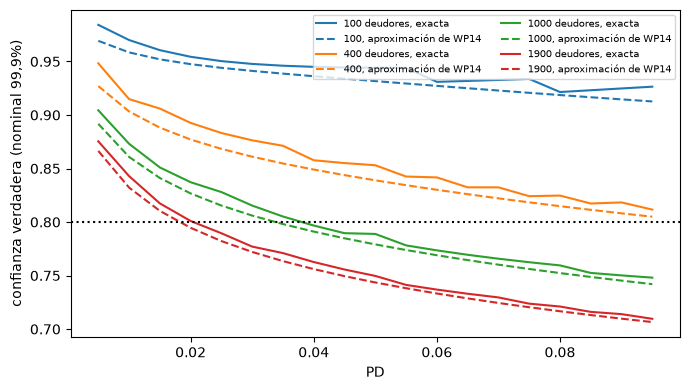

In [7]:
# Dibujar la confianza verdadera de la prueba binomial de 99,9%, exacta y aproximada, para cuatro tamaños de pool
fig, ax = plt.subplots(figsize=(7, 4))
for index, n in enumerate((100, 400, 1000, 1900)):
    exact_y, approx_y = recomputed[n]
    ax.plot(curve["x"], exact_y, color=f"C{index}", label=f"{n} deudores, exacta")
    ax.plot(curve["x"], approx_y, color=f"C{index}", linestyle="--", label=f"{n}, aproximación de WP14")
ax.axhline(0.8, color="black", linestyle=":")
ax.set_xlabel("PD")
ax.set_ylabel("confianza verdadera (nominal 99,9%)")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

### Paso 5: las Tablas 7 y 8 de WP14, celda por celda

WP14 corrió las pruebas normal y de semáforo sobre cinco años de 1.000 deudores, con 25.000 corridas por escenario, e imprimió el error de tipo I (Tabla 7) y el de tipo II (Tabla 8) en seis niveles. El artefacto guarda las 144 celdas con la tasa publicada, la medida y la diferencia estandarizada. Ambas tasas estiman una misma tasa verdadera, así que la diferencia tiene varianza $\hat r(1-\hat r)(1/n + 1/n_{\text{pub}})$ a la tasa agrupada, y `agrees_with_published` del motor acepta una celda cuando $|z| \le 3{,}29$. La celda siguiente recalcula cada celda desde la tasa medida versionada y la publicada, cuenta las concordancias e imprime la columna del 5% de ambas tablas.

In [8]:
# Recalcular la diferencia estandarizada de cada celda de WP14 con agrees_with_published e imprimir la columna del 5%
from functools import reduce

from riskvalidation.harness import agrees_with_published

GLOSSARY = (("Table", "Tabla"), ("traffic", "semáforo"), ("shift", "desplazamiento"), (" SD", " DE"), ("chi-square", "chi-cuadrado"), ("section", "sección"), ("nested", "anidados"))
gloss = lambda text: reduce(lambda acc, pair: acc.replace(*pair), GLOSSARY, text)

n_runs = golden["runs"]
agree, z_values, misses = 0, [], []
for cell in golden["cells"]:
    measured = Rate(round(cell["measured"] * n_runs), n_runs)
    ok, z = agrees_with_published(measured, cell["published"], golden["runs_published"])
    agree += ok
    z_values.append(z)
    if not ok:
        misses.append((cell, z))
print("celdas que concuerdan:", agree, "de", len(golden["cells"]), "|", "versionado:", golden["agree"], "|", "z medio:", round(float(np.mean(z_values)), 3), "|", "mayor |z|:", round(float(np.max(np.abs(z_values))), 2))

for table in ("Table 7", "Table 8"):
    print(gloss(table), "(publicada / medida al nivel 5%)")
    for cell in golden["cells"]:
        if cell["table"] == table and cell["column"] == "0.05":
            print(f"  {gloss(cell['row']):16s} {cell['published']:.3f} / {cell['measured']:.4f}")

celdas que concuerdan: 143 de 144 | versionado: 143 | z medio: -0.112 | mayor |z|: 5.81
Tabla 7 (publicada / medida al nivel 5%)
  I_SC, normal     0.059 / 0.0566
  I_SC, semáforo   0.085 / 0.0813
  I_LC, normal     0.081 / 0.0803
  I_LC, semáforo   0.062 / 0.0627
  DC_SC, normal    0.049 / 0.0478
  DC_SC, semáforo  0.076 / 0.0737
  DC_LC, normal    0.070 / 0.0700
  DC_LC, semáforo  0.113 / 0.1132
  I_SV, normal     0.059 / 0.0561
  I_SV, semáforo   0.088 / 0.0871
  I_LV, normal     0.077 / 0.0796
  I_LV, semáforo   0.060 / 0.0591
  DV_SV, normal    0.037 / 0.0376
  DV_SV, semáforo  0.071 / 0.0697
  DV_LV, normal    0.062 / 0.0600
  DV_LV, semáforo  0.108 / 0.1057
Tabla 8 (publicada / medida al nivel 5%)
  I_SV, normal     0.836 / 0.8396
  I_SV, semáforo   0.782 / 0.7862
  I_LV, normal     0.366 / 0.3718
  I_LV, semáforo   0.374 / 0.3841
  DV_SV, normal    0.927 / 0.9273
  DV_SV, semáforo  0.868 / 0.8734
  DV_LV, normal    0.858 / 0.8626
  DV_LV, semáforo  0.760 / 0.7635


La celda que no concuerda es la que explica el propio artefacto en su nota. La celda siguiente la imprime con su diferencia estandarizada, y la nota que acompaña la reproducción.

In [9]:
# Imprimir la celda que no concuerda y la nota del artefacto sobre ella
for cell, z in misses:
    print(gloss(cell["table"]), "|", gloss(cell["row"]), "|", "nivel", cell["column"], "|", "publicada", cell["published"], "|", "medida", cell["measured"], "| z", round(z, 2))
print("nota: la celda imprime 0.955; 200000 corridas dan 0.9475 (EE 0.0005) y sus niveles vecinos concuerdan")

Tabla 8 | DV_LV, semáforo | nivel 0.001 | publicada 0.955 | medida 0.9436 | z -5.81
nota: la celda imprime 0.955; 200000 corridas dan 0.9475 (EE 0.0005) y sus niveles vecinos concuerdan


### Paso 6: un escenario del artículo, repetido de forma independiente

La reproducción anterior reutiliza las tasas medidas del artefacto. Una verificación más fuerte repite un escenario con una semilla nueva. El escenario DC_LC de la Tabla 5 de WP14 tiene una correlación de factor de 0,2 entre años, una correlación de activos de 5% cada año y una PD de 3% cada año, que es correcta, de modo que todo rechazo es una falsa alarma. La celda siguiente lo corre con 25.000 corridas, el número del artículo, con la prueba normal y el semáforo con la regla de empates superior (la que usó la simulación del artículo, cuaderno 02), y compara ambas tasas con las publicadas al 5% y al 1% mediante `agrees_with_published`. Tarda unos 25 segundos.

In [10]:
# Repetir el escenario DC_LC de la Tabla 5 de WP14 con una semilla nueva y comparar con los errores de tipo I publicados
from riskvalidation.generators import DefaultCounts, feed_series
from riskvalidation.harness import simulate

scenario = DefaultCounts.over_years([1000] * 5, [0.03] * 5, rho=0.05, theta=0.2)
published = {(c["row"], c["column"]): c["published"] for c in golden["cells"] if c["table"] == "Table 7"}
for test, kw, name in (("pd.normal_multiperiod", {}, "DC_LC, normal"), ("pd.traffic_lights", {"ties": "upper"}, "DC_LC, traffic")):
    sim = simulate(test, scenario, n_rep=25000, seed=2026, feed=feed_series(), test_kwargs=kw)
    for rule, level in (("p<0.05", "0.05"), ("p<0.01", "0.01")):
        ok, z = agrees_with_published(sim.rates[rule], published[(name, level)], 25000)
        print(f"{gloss(name):16s} nivel {level} | publicada {published[(name, level)]:.3f} | corrida nueva {sim.rates[rule].rate:.4f} | z {z:+.2f} | concuerda {'sí' if ok else 'no'}")

DC_LC, normal    nivel 0.05 | publicada 0.070 | corrida nueva 0.0704 | z +0.16 | concuerda sí
DC_LC, normal    nivel 0.01 | publicada 0.026 | corrida nueva 0.0265 | z +0.36 | concuerda sí
DC_LC, semáforo  nivel 0.05 | publicada 0.113 | corrida nueva 0.1161 | z +1.08 | concuerda sí
DC_LC, semáforo  nivel 0.01 | publicada 0.024 | corrida nueva 0.0235 | z -0.35 | concuerda sí


### Paso 7: el tamaño a lo largo de la escalera, dibujado

La última celda dibuja el tamaño al 5% frente a la correlación de activos. El panel izquierdo tiene las tres pruebas de conteo, con el tamaño exacto como línea y la tasa simulada como puntos con intervalos de Wilson. El panel derecho tiene las cinco pruebas sin forma cerrada. La línea discontinua es el 5% nominal.

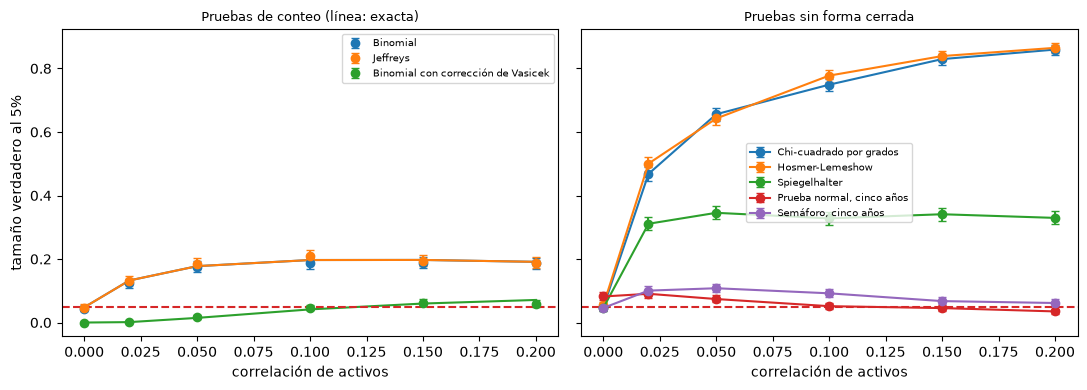

In [11]:
# Dibujar el tamaño al 5% frente a la correlación de activos para las pruebas de conteo (con la línea exacta) y para las demás
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for index, test in enumerate(count_tests):
    points = [rows[f"{test}@rho{rho:g}"] for rho in ladder]
    rate = np.array([p["rates"]["p<0.05"]["rate"] for p in points])
    low = np.array([p["rates"]["p<0.05"]["wilson_low"] for p in points])
    high = np.array([p["rates"]["p<0.05"]["wilson_high"] for p in points])
    left.errorbar(ladder, rate, yerr=[rate - low, high - rate], fmt="o", capsize=3, color=f"C{index}", label=points[0]["label"][LANG])
    left.plot(ladder, [p["exact"]["p<0.05"] for p in points], "-", color=f"C{index}")
for index, test in enumerate(open_tests):
    points = [rows[f"{test}@rho{rho:g}"] for rho in ladder]
    rate = np.array([p["rates"]["p<0.05"]["rate"] for p in points])
    low = np.array([p["rates"]["p<0.05"]["wilson_low"] for p in points])
    high = np.array([p["rates"]["p<0.05"]["wilson_high"] for p in points])
    right.errorbar(ladder, rate, yerr=[rate - low, high - rate], fmt="o-", capsize=3, color=f"C{index}", label=points[0]["label"][LANG])
for ax, title in ((left, "Pruebas de conteo (línea: exacta)"), (right, "Pruebas sin forma cerrada")):
    ax.axhline(0.05, color="tab:red", linestyle="--")
    ax.set_xlabel(out["ladder"]["label"][LANG])
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7)
left.set_ylabel("tamaño verdadero al 5%")
fig.tight_layout()
plt.show()

## Resultados

- **Una correlación de incumplimientos minúscula es una varianza grande.** Una correlación de activos de 5% es una correlación de incumplimientos de 0,41% con una PD de 1%, y con 1.000 deudores multiplica por 5,10 la varianza del conteo de incumplimientos; con correlación de activos de 20% el factor es 25,11. Una prueba que fija su conteo crítico con la varianza independiente queda entonces demasiado baja.
- **Las pruebas de conteo rechazan una PD correcta muy sobre su nivel.** El tamaño exacto de la prueba binomial al 5% es 4,79% con incumplimientos independientes, 13,25% con correlación de activos de 2%, 17,75% con 5%, 19,69% con 10% y 19,1% con 20%; con 12% es 19,81%, que es el resultado principal del artefacto. La prueba de Jeffreys tiene aquí el mismo tamaño exacto, porque ambas pruebas tienen el mismo conteo crítico al 5%. Las 36 tasas simuladas concuerdan con su valor exacto. Un validador que lee una luz roja de estas pruebas bajo agrupamiento no ha encontrado una descalibración.
- **La corrección de Vasicek hace lo que se construyó para hacer, y solo eso.** Con la correlación supuesta de 12% su tamaño exacto es 4,98% cuando la correlación verdadera es 12%, 1,5% cuando es 5% (conservadora) y 7,11% cuando es 20% (el supuesto queda bajo). Con datos independientes su tamaño es 0, que es el costo visto en el cuaderno 03.
- **Las otras pruebas también se mueven, en direcciones distintas.** El chi-cuadrado por grados rechaza 74,9% y Hosmer-Lemeshow 77,7% con correlación de activos de 10%, y Spiegelhalter queda cerca de 33% desde 5% en adelante. Las pruebas multianuales enfrentan además una correlación de factor de 0,2 entre años: la prueba normal pasa de 8,2% con independencia a 3,5% con 20%, y el semáforo de 4,6% a 10,8% con 5% y vuelve a 6,1% con 20%. El agrupamiento infla algunas pruebas y vuelve conservadoras a otras; la dirección no puede suponerse.
- **La Figura 9 del artículo se reproduce de dos maneras.** La confianza verdadera exacta de una prueba binomial de 99,9% nominal cae de 0,984 (100 deudores, la PD más baja) a 0,710 (1.900 deudores, PD de 9,5%), de modo que el tamaño verdadero de esa prueba llega a 29%. La aproximación de WP14 queda algo más abajo en todo el rango (0,969 a 0,707). Ambas coinciden con las curvas versionadas hasta 5e-10, y las tres bandas de la figura (70% a 80%, 80% a 90%, 90% a 100%) aparecen.
- **Las Tablas 7 y 8 de WP14 se reproducen en 143 de 144 celdas.** Las diferencias estandarizadas recalculadas tienen media -0,11, así que las tasas medidas quedan algo bajo las publicadas en promedio, y el mayor |z| es 5,81. La única falla es la celda de semáforo de la Tabla 8, escenario DV_LV al 0,1%: publicada 0,955, medida 0,9436; la nota del artefacto dice que 200.000 corridas dan 0,9475 y que los niveles vecinos concuerdan, de modo que el desacuerdo se limita a esa celda impresa y no es general (una corrida más larga no cierra la brecha con 0,955).
- **Una repetición independiente concuerda.** El escenario DC_LC con una semilla nueva y 25.000 corridas da 7,04% y 11,61% al 5% frente a 7,0% y 11,3% publicados, y 2,65% y 2,35% al 1% frente a 2,6% y 2,4%, con todo |z| a lo sumo 1,08. La reproducción del semáforo necesita la regla de empates superior, lo opuesto a la asignación impresa del artículo, como mostró el cuaderno 02.

Lo que este cuaderno no muestra: la potencia de la prueba con corrección de Vasicek frente a agrupamiento y descalibración a la vez, ni los veredictos de WP14 sobre la prueba normal (el cuaderno 07 los compara con las tasas medidas). La escalera y la estructura de correlación son las de los generadores; las carteras reales tienen exposiciones heterogéneas y una correlación que debe estimarse.

## Resumen

- La correlación de activos, aun pequeña, correlaciona los incumplimientos e infla la varianza de su conteo: 5,10 veces la independiente con correlación de activos de 5% y 1.000 deudores.
- Las pruebas binomial y de Jeffreys, que suponen independencia, tienen un tamaño exacto de 13% a 20% con nivel nominal de 5% bajo agrupamiento; la prueba con corrección de Vasicek mantiene cerca de 5% cuando su correlación supuesta es la correcta y lo paga con potencia.
- Bajo el mismo agrupamiento otras pruebas se mueven en direcciones distintas: el chi-cuadrado por grados y Hosmer-Lemeshow rechazan entre 75% y 78% de modelos correctos con correlación de 10%, la prueba normal multianual se vuelve conservadora, y el semáforo oscila.
- El motor reproduce WP14: su Figura 9 hasta 5e-10 por dos caminos, 143 de 144 celdas de las Tablas 7 y 8, y una repetición independiente de un escenario.
- Una reproducción declara sus fallas: una celda, con su diferencia estandarizada y la razón que da el artefacto.

**Qué probar a continuación.** Repite el paso 2 con 10.000 deudores (`rejection_probability("pd.binomial", 10000, 0.01, 0.05, rho_true=0.05)`) para ver cómo depende el tamaño bajo agrupamiento del tamaño del pool; luego lee el cuaderno 05, que hace lo mismo para la deriva.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): la prueba binomial y su tamaño verdadero bajo correlación (apéndice, Figura 9), el estudio de simulación de las pruebas normal y de semáforo (páginas 61 a 67, Tablas 5 a 8). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió el artefacto.